In [1]:
import utils

import torch
from torch import nn

device = torch.device("mps" if torch.mps.is_available() else "cpu")
torch.set_default_device(device)

# Loading the CIFAR10 dataset and create DataLoaders

In [2]:
batch_size = 256
train_iter, test_iter = utils.load_data_cifar10(batch_size)


# Defining the Model

In [3]:
class MathisBlock(nn.Module):
    def __init__(self, input_channels, num_convs, factor):
        super(MathisBlock, self).__init__()
        reduced_channels = input_channels // factor

        self.expertBranch = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(input_channels, reduced_channels),
            nn.ReLU(),
            nn.Linear(reduced_channels, num_convs),
            nn.Softmax(dim=-1)
        )

        self.convs = nn.ModuleList([
            nn.Conv2d(input_channels, input_channels, kernel_size=3, padding=1)
            for _ in range(num_convs)
        ])

        self.bns = nn.ModuleList([
            nn.BatchNorm2d(input_channels)
            for _ in range(num_convs)
        ])

        self.num_convs = num_convs

    def forward(self, x):
        a = self.expertBranch(x)
        out = 0
        for i, (conv, bn) in enumerate(zip(self.convs, self.bns)):
            y = conv(x)
            y = bn(y)
            weight = a[:, i].view(-1, 1, 1, 1)
            out += weight * y
        return x + out # allowed ?

class MathisNet(nn.Module):
    def __init__(self, conv_arch, num_outputs):
        super(MathisNet, self).__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 64, 5, padding=2), nn.BatchNorm2d(64), nn.ReLU())

        in_channels = 64
        self.blocks = nn.ModuleList()
        for num_convs, factor in conv_arch:
            block = MathisBlock(in_channels, num_convs, factor)
            self.blocks.append(block)

        self.last = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(in_channels, 4096),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(4096, 1000),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(1000, num_outputs)
        )

    def forward(self, x):
        x = self.stem(x)
        for block in self.blocks:
            x = block(x)
        x = self.last(x)
        return x


# Initialise Model and Weights

In [5]:
def init_weights(m):
    if type(m) == nn.Linear or type(m) == nn.Conv2d: # by checking thr type we can init different layers in different ways
        torch.nn.init.kaiming_normal_(m.weight)

conv_arch = ((10, 2), (10, 2), (10, 2))
num_outputs = 10
model = MathisNet(conv_arch, num_outputs)

model.apply(init_weights)
print(model)

MathisNet(
  (stem): Sequential(
    (0): Conv2d(3, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
  )
  (blocks): ModuleList(
    (0-2): 3 x MathisBlock(
      (expertBranch): Sequential(
        (0): AdaptiveAvgPool2d(output_size=(1, 1))
        (1): Flatten(start_dim=1, end_dim=-1)
        (2): Linear(in_features=64, out_features=32, bias=True)
        (3): ReLU()
        (4): Linear(in_features=32, out_features=10, bias=True)
        (5): Softmax(dim=-1)
      )
      (convs): ModuleList(
        (0-9): 10 x Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      )
      (bns): ModuleList(
        (0-9): 10 x BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
  )
  (last): Sequential(
    (0): AdaptiveAvgPool2d(output_size=(1, 1))
    (1): Flatten(start_dim=1, end_dim=-1)
    (2): Linear(in_features=64, out_featu

# Loss and Optimisation Algorithms

In [6]:
loss = nn.CrossEntropyLoss()
lr = 0.01
optimiser = torch.optim.SGD(model.parameters(), lr=lr)

# Training functions

KeyboardInterrupt: 

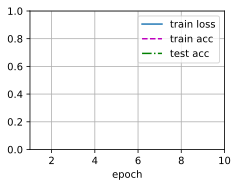

In [7]:
num_epochs = 10
utils.train(model, train_iter, test_iter, loss, num_epochs, optimiser)